# Explore the turnover gap

A notebook for questions the Code block doesn't answer. Each cell runs in ros.ai's Python sandbox on this computer and reads the data file from the project folder.

In [1]:
import pandas as pd

df = pd.read_csv('../data/CBS AI use by company size 2024.csv')
df[['size_group', 'ai_enterprise_percent', 'adopter_turnover_percent']]

,size_group,ai_enterprise_percent,adopter_turnover_percent
0,10-19,17.8,18.7
1,20-49,22.2,21.6
2,50-99,28.1,27.8
3,100-249,34.8,43.7
4,250-499,46.2,60.5
5,500+,59.2,79.5


Where do AI users hold a larger share of turnover than their share of firms?

In [2]:
df['gap_pp'] = (df.adopter_turnover_percent - df.ai_enterprise_percent).round(1)
df[['size_group', 'gap_pp']]

,size_group,gap_pp
0,10-19,0.9
1,20-49,-0.6
2,50-99,-0.3
3,100-249,8.9
4,250-499,14.3
5,500+,20.3


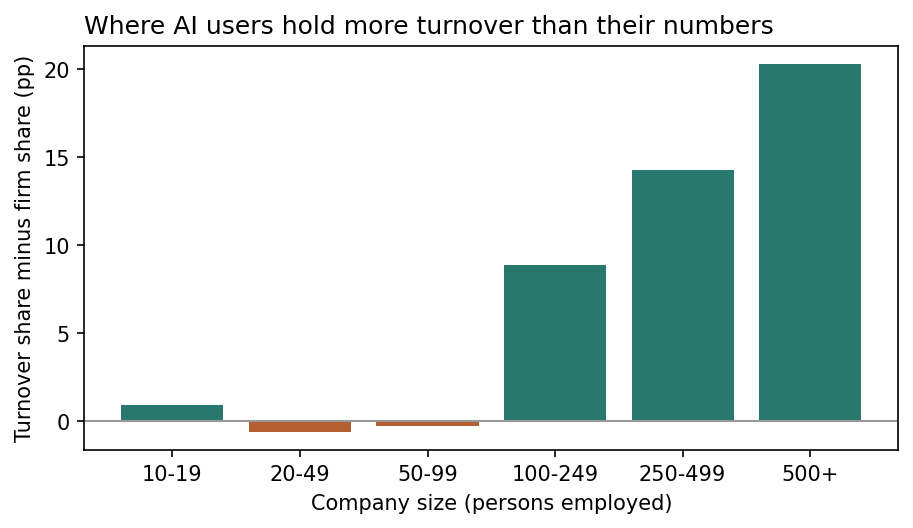

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(df.size_group, df.gap_pp, color=['#b35f32' if v < 0 else '#28786e' for v in df.gap_pp])
ax.axhline(0, color='#999999', lw=1)
ax.set_xlabel('Company size (persons employed)')
ax.set_ylabel('Turnover share minus firm share (pp)')
ax.set_title('Where AI users hold more turnover than their numbers', loc='left')
plt.show()

Two middle groups, 20–49 and 50–99 employees, sit just below zero. The largest firms are 20.3 points above. Turnover that belongs to AI users is not turnover caused by AI.